# Regional Pacific chlorophyll-a

Regional counterpart of `National/biochemistry/b_chlorophyll.ipynb`. The workflow maps the
mean, seasonal cycle, anomalies and linear trend of **Chlorophyll-a**, overlays
Pacific EEZ boundaries, calculates area-weighted regional and EEZ summaries, and
compares ENSO phases using the project's five-consecutive-month ONI rule.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings('ignore')

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import xarray as xr
from matplotlib.path import Path as MplPath
from scipy import stats

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions').is_dir() and (p / 'data').is_dir()), None)
if repo_root is None:
    raise FileNotFoundError('Run this notebook from inside the CIndRA repository.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from functions.data_downloaders import download_oni_index
from functions.ocean import process_trend_with_nan

plt.rcParams.update({'font.size': 12, 'axes.titlesize': 15, 'axes.labelsize': 14,
                     'xtick.labelsize': 12, 'ytick.labelsize': 12,
                     'legend.fontsize': 13})

## 1. Configuration and data

Regional NetCDF files are cached at `data/regional/biochemistry/`. The source is
downloaded automatically when absent. National subsets are never used in this
regional workflow. Coordinates may be named `lon`/`lat` or
`longitude`/`latitude`.

In [3]:
variable = 'chl'
label = 'Chlorophyll-a'
units = 'mg m⁻³'
cmap = 'YlGn'
pacific_extent = (125, 245, -35, 35)
trend_period = (1993, 2025)
reference_period = (1993, 2020)
regional_file = 'copernicus_bgc_pacific_surface_monthly.nc'
data_dir = repo_root / 'data'
regional_dir = data_dir / 'regional' / 'biochemistry'
fig_dir = repo_root / 'matrix_cc' / 'figures'
regional_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

eez_file = data_dir / 'regional' / 'Pacific_EEZs' / 'Pacific_EEZs.shp'
if not eez_file.is_file():
    raise FileNotFoundError(f'Pacific EEZ shapefile not found: {eez_file}')

regional_path = regional_dir / regional_file

### Automatic Copernicus Marine download

The four Copernicus workflows for pH, chlorophyll-a, phytoplankton biomass and dissolved oxygen share
one surface-biogeochemistry cache. If it is absent, this cell downloads all
four variables (`chl`, `ph`, `phyc`, `o2`) for the Pacific domain. Copernicus
Marine credentials must already be configured on the computer. Run
`copernicusmarine login` once in a terminal before executing the notebook;
credentials are intentionally never written in the notebook.

In [4]:
import copernicusmarine
from packaging.version import Version

if Version(copernicusmarine.__version__) < Version('2.2.0'):
    raise RuntimeError(
        f'copernicusmarine {copernicusmarine.__version__} is incompatible '
        'with the installed Zarr stack. Install copernicusmarine>=2.2.0 '
        'and restart the kernel.'
    )

copernicus_dataset_id = 'cmems_mod_glo_bgc_my_0.25deg_P1M-m'
copernicus_variables = ['chl', 'ph', 'phyc', 'o2']
copernicus_start = '1993-01-01T00:00:00'
copernicus_end = '2026-05-01T00:00:00'
surface_depth = 0.5057600140571594

if not regional_path.is_file():
    credentials_valid = copernicusmarine.login(check_credentials_valid=True)
    if not credentials_valid:
        raise RuntimeError(
            'Copernicus Marine credentials were not found or are invalid. '
            'Run this command in Terminal and then execute this cell again: '
            '/Users/laurac/opt/anaconda3/envs/cc_indicators_v2/bin/'
            'copernicusmarine login'
        )
    # Copernicus longitudes are -180..180, whereas the regional maps use
    # 0..360. Download either side of the dateline and merge afterwards.
    download_parts = [
        ('west', pacific_extent[0], 179.75),
        ('east', -180.0, pacific_extent[1] - 360.0),
    ]
    part_paths = []
    for suffix, minimum_lon, maximum_lon in download_parts:
        part_name = f'copernicus_bgc_pacific_{suffix}.nc'
        part_path = regional_dir / part_name
        part_paths.append(part_path)
        if part_path.is_file():
            print(f'Using completed download part: {part_path}')
            continue
        print(f'Downloading Copernicus Marine longitudes {minimum_lon} to {maximum_lon} ...')
        copernicusmarine.subset(
            dataset_id=copernicus_dataset_id,
            variables=copernicus_variables,
            minimum_longitude=minimum_lon,
            maximum_longitude=maximum_lon,
            minimum_latitude=pacific_extent[2],
            maximum_latitude=pacific_extent[3],
            start_datetime=copernicus_start,
            end_datetime=copernicus_end,
            minimum_depth=surface_depth,
            maximum_depth=surface_depth,
            coordinates_selection_method='outside',
            output_directory=regional_dir,
            output_filename=part_name,
            file_format='netcdf',
            netcdf_compression_level=4,
            skip_existing=True,
        )

    pieces = []
    for part_path in part_paths:
        if not part_path.is_file():
            raise FileNotFoundError(f'Copernicus download did not create {part_path}')
        with xr.open_dataset(part_path) as part:
            part = part.load()
        part = part.assign_coords(
            longitude=xr.where(part.longitude < 0, part.longitude + 360, part.longitude)
        )
        pieces.append(part)
    combined = xr.concat(pieces, dim='longitude').sortby('longitude')
    combined = combined.isel(
        longitude=~combined.get_index('longitude').duplicated()
    )
    final_temporary = regional_path.with_suffix('.nc.part')
    combined.to_netcdf(final_temporary)
    final_temporary.replace(regional_path)
    for part_path in part_paths:
        part_path.unlink(missing_ok=True)
    if not regional_path.is_file():
        raise FileNotFoundError(
            f'Copernicus Marine finished without creating {regional_path}'
        )
else:
    print(f'Using cached Copernicus Marine file: {regional_path}')

Using cached Copernicus Marine file: /Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/data/regional/biochemistry/copernicus_bgc_pacific_surface_monthly.nc


In [5]:
if not regional_path.is_file():
    raise FileNotFoundError(
        f'Regional download is missing: {regional_path}. '
        'Review the download-cell output before continuing.'
    )
source_path = regional_path
is_regional_dataset = True
print('Data:', source_path)
print('Source: Copernicus Marine biogeochemical reanalysis')
print('Reference: https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_BGC_001_029/description')

Data: /Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/data/regional/biochemistry/copernicus_bgc_pacific_surface_monthly.nc
Source: Copernicus Marine biogeochemical reanalysis
Reference: https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_BGC_001_029/description


In [6]:
ds = xr.open_dataset(source_path)
rename = {}
if 'lon' in ds.coords: rename['lon'] = 'longitude'
if 'lat' in ds.coords: rename['lat'] = 'latitude'
ds = ds.rename(rename)
if variable not in ds:
    raise KeyError(f'{variable!r} is not present in {source_path.name}: {list(ds.data_vars)}')
if 'depth' in ds[variable].dims:
    ds = ds.isel(depth=0, drop=True)
field = ds[variable].sortby('time').sortby('latitude').sortby('longitude')
field = field.sel(time=slice(str(trend_period[0]), str(trend_period[1])))
field = field.where(np.isfinite(field))

eez = gpd.read_file(eez_file).to_crs(4326)
country_col = next((c for c in ('Country', 'GEONAME', 'SOVEREIGN1', 'TERRITORY1') if c in eez.columns), None)
if country_col is None:
    eez['Country'] = eez.index.astype(str)
    country_col = 'Country'

data_extent = (float(field.longitude.min()), float(field.longitude.max()),
               float(field.latitude.min()), float(field.latitude.max()))
map_extent = pacific_extent if is_regional_dataset else data_extent
print(f'Coverage: {data_extent}; {field.sizes["time"]} months')

Coverage: (125.0, 245.0, -35.0, 35.0); 396 months


## 2. Map helpers and long-term mean

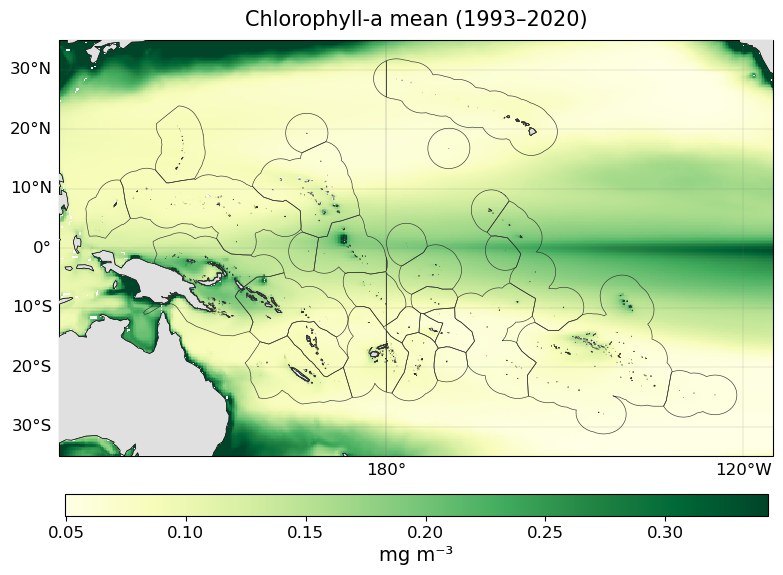

In [7]:
def setup_map(ax, title):
    ax.set_extent(map_extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='0.88', edgecolor='0.35', linewidth=0.4, zorder=3)
    ax.coastlines(linewidth=0.45, zorder=4)
    eez.boundary.plot(ax=ax, transform=ccrs.PlateCarree(), color='0.2', linewidth=0.45, zorder=5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.25, color='0.45', alpha=0.5)
    gl.top_labels = gl.right_labels = False
    ax.set_title(title, pad=10)
    return ax

def map_field(values, title, colour_map, cbar_label, symmetric=False):
    finite = np.asarray(values.values)[np.isfinite(values.values)]
    if not len(finite):
        raise ValueError('No finite values are available for this map.')
    if symmetric:
        lim = float(np.nanpercentile(np.abs(finite), 98))
        vmin, vmax = -lim, lim
    else:
        vmin, vmax = np.nanpercentile(finite, [2, 98])
    fig, ax = plt.subplots(figsize=(15, 6), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})
    setup_map(ax, title)
    im = ax.pcolormesh(values.longitude, values.latitude, values, transform=ccrs.PlateCarree(),
                       cmap=colour_map, vmin=vmin, vmax=vmax, shading='auto')
    cb = fig.colorbar(
        im, ax=ax, orientation='horizontal', pad=0.07,
        shrink=0.48, aspect=32,
    )
    cb.set_label(cbar_label, fontsize=14)
    fig.tight_layout()
    return fig

climatology = field.sel(time=slice(str(reference_period[0]), str(reference_period[1]))).mean('time')
fig_mean = map_field(climatology, f'{label} mean ({reference_period[0]}–{reference_period[1]})', cmap, units)
fig_mean.savefig(fig_dir / f'regional_{variable}_mean.png', dpi=150, bbox_inches='tight')

## 3. Linear trend

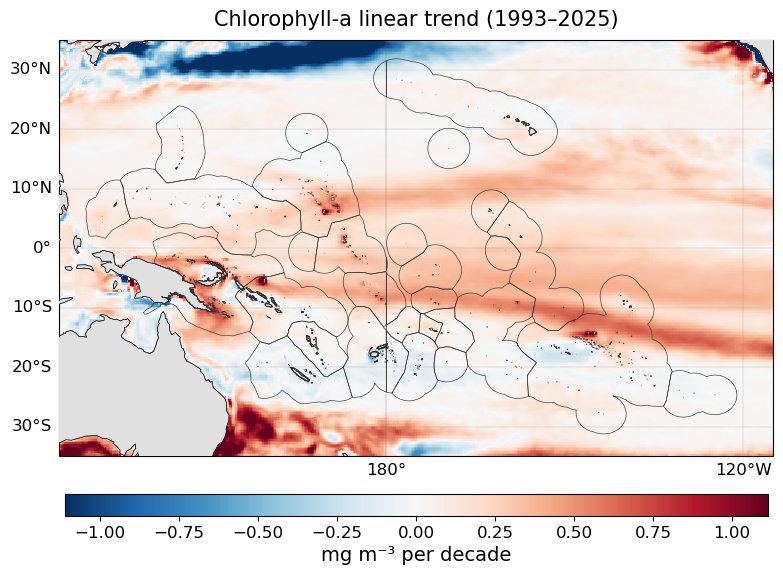

In [8]:
annual = field.resample(time='YS').mean()
trend, _, _, _, _ = process_trend_with_nan(annual)
trend = xr.DataArray(trend * 10, coords={'latitude': annual.latitude, 'longitude': annual.longitude},
                     dims=('latitude', 'longitude'))
fig_trend = map_field(trend, f'{label} linear trend ({trend_period[0]}–{trend_period[1]})',
                      'RdBu_r', f'{units} per decade', symmetric=True)
fig_trend.savefig(fig_dir / f'regional_{variable}_trend.png', dpi=150, bbox_inches='tight')

## 4. Seasonal climatology and anomalies

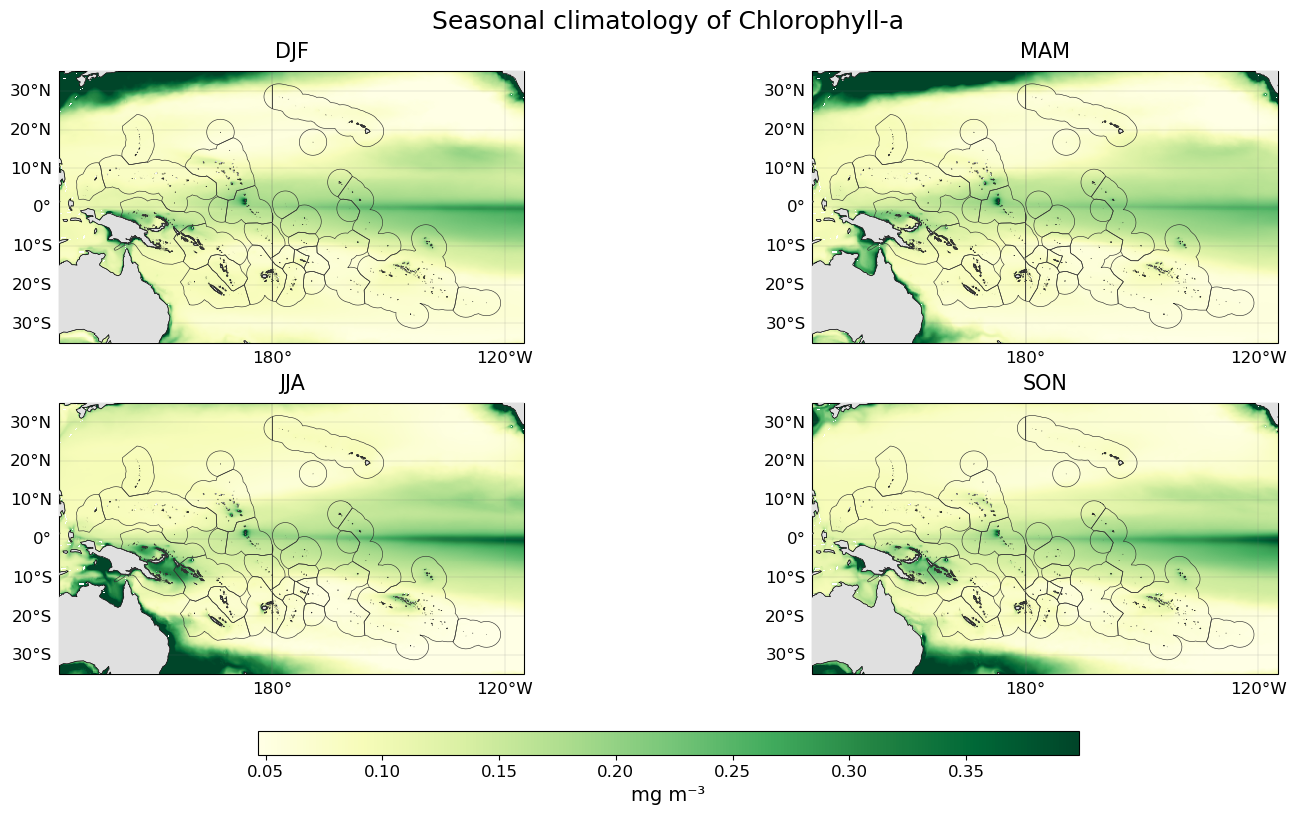

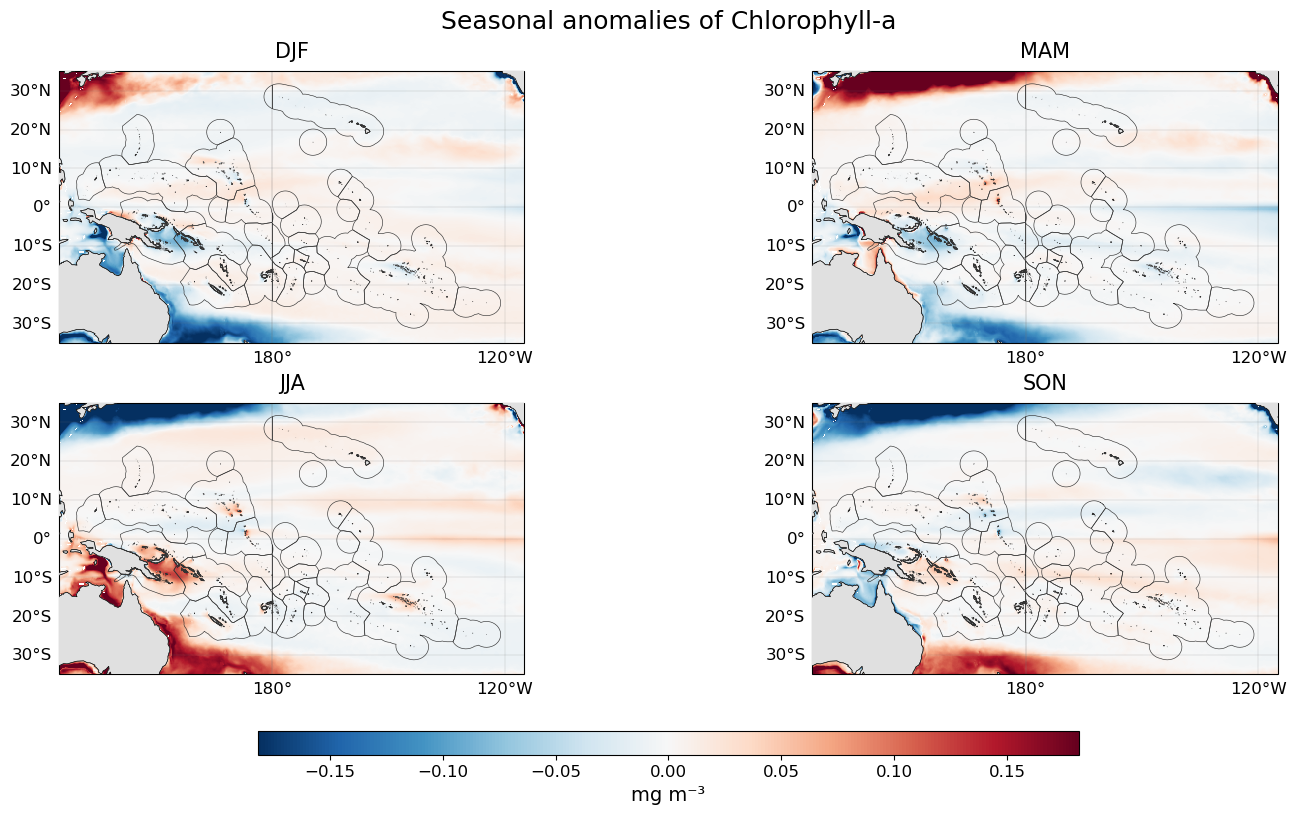

In [9]:
seasonal = field.groupby('time.season').mean().sel(season=['DJF', 'MAM', 'JJA', 'SON'])
seasonal_anomaly = seasonal - climatology

def seasonal_panels(values, title, colour_map, symmetric=False):
    finite = values.values[np.isfinite(values.values)]
    if symmetric:
        lim = float(np.nanpercentile(np.abs(finite), 98)); vmin, vmax = -lim, lim
    else:
        vmin, vmax = np.nanpercentile(finite, [2, 98])
    fig, axes = plt.subplots(2, 2, figsize=(15, 8),
        subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)}, constrained_layout=True)
    for ax, season in zip(axes.flat, values.season.values):
        setup_map(ax, str(season))
        im = ax.pcolormesh(values.longitude, values.latitude, values.sel(season=season),
                           transform=ccrs.PlateCarree(), cmap=colour_map,
                           vmin=vmin, vmax=vmax, shading='auto')
    fig.suptitle(title, fontsize=18)
    cb = fig.colorbar(
        im, ax=axes, orientation='horizontal', pad=0.05,
        shrink=0.55, aspect=35,
    )
    cb.set_label(units, fontsize=14)
    return fig

fig_season = seasonal_panels(seasonal, f'Seasonal climatology of {label}', cmap)
fig_season.savefig(fig_dir / f'regional_{variable}_seasonal.png', dpi=150, bbox_inches='tight')
fig_season_anom = seasonal_panels(seasonal_anomaly, f'Seasonal anomalies of {label}', 'RdBu_r', True)
fig_season_anom.savefig(fig_dir / f'regional_{variable}_seasonal_anomaly.png', dpi=150, bbox_inches='tight')

## 5. Area-weighted regional time series

In [10]:
weights = np.cos(np.deg2rad(field.latitude))
regional_monthly = field.weighted(weights).mean(('latitude', 'longitude'))
regional_annual = regional_monthly.resample(time='YS').mean()
x_dates = pd.DatetimeIndex(regional_annual.time.values)
x = x_dates.year.to_numpy()
y = regional_annual.values
valid = np.isfinite(y)
trend_result = stats.linregress(x[valid], y[valid])
slope = trend_result.slope
significant = trend_result.pvalue < 0.05
trend_style = 'solid' if significant else 'dash'
significance_text = 'Significant (p < 0.05)' if significant else 'Not significant (p ≥ 0.05)'

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=x_dates, y=y, mode='lines+markers', name='Area-weighted annual mean',
    line=dict(color='#1f77b4', width=2), marker=dict(size=7),
    hovertemplate='%{x|%Y}<br>%{y:.4g} ' + units + '<extra></extra>',
))
fig.add_trace(go.Scatter(
    x=x_dates[valid], y=trend_result.intercept + slope*x[valid], mode='lines',
    line=dict(color='black', width=2.5, dash=trend_style),
    name=f'Trend (rate = {slope*10:+.3g} {units}/decade) – {significance_text}',
    hovertemplate='Trend %{x|%Y}<br>%{y:.4g} ' + units + '<extra></extra>',
))
fig.update_layout(
    title=dict(text=f'Regional annual {label}', x=0.5, xanchor='center'),
    xaxis=dict(title='Year', range=[x_dates[valid].min(), x_dates[valid].max()], showgrid=True),
    yaxis=dict(title=units, showgrid=True), template='plotly_white',
    width=1000, height=500, hovermode='x unified',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='center', x=0.5, font=dict(size=13)),
    margin=dict(l=75, r=35, t=110, b=65),
)
fig.write_html(fig_dir / f'regional_{variable}_timeseries.html', include_plotlyjs='cdn')
fig.show()

## 6. ENSO modulation

El Niño and La Niña episodes require at least five consecutive months with ONI
above +0.5 °C or below −0.5 °C, respectively. Other months remain Neutral.
Each phase composite is shown as an anomaly from the grid-cell mean over the
complete analysis period, rather than as a difference from the Neutral phase.

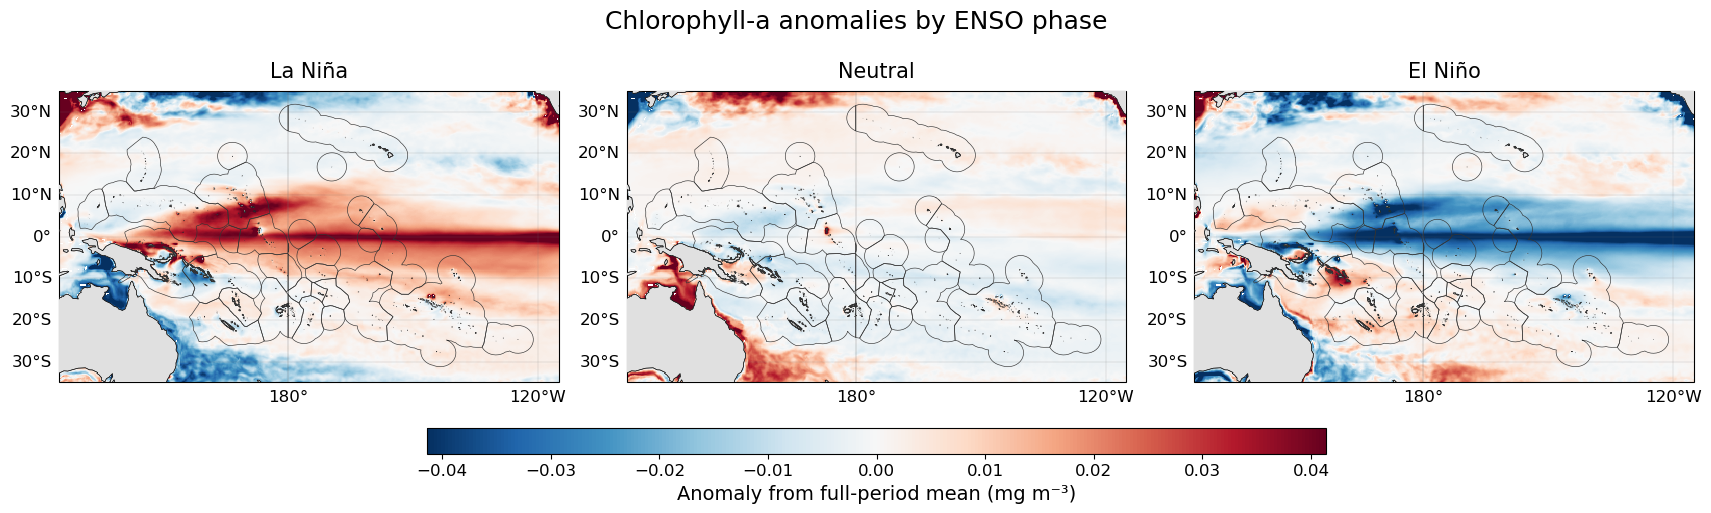

In [11]:
oni_cache = regional_dir / 'oni_index.pkl'
if oni_cache.is_file():
    oni = pd.read_pickle(oni_cache)
else:
    oni = download_oni_index('https://psl.noaa.gov/data/correlation/oni.data')
    oni.to_pickle(oni_cache)
oni = oni.rename(columns={oni.columns[0]: 'ONI'})[['ONI']].copy()

def sustained(mask, minimum=5):
    groups = mask.ne(mask.shift()).cumsum()
    lengths = mask.groupby(groups).transform('sum')
    return mask & (lengths >= minimum)

oni['phase'] = 'Neutral'
oni.loc[sustained(oni.ONI >= .5), 'phase'] = 'El Nino'
oni.loc[sustained(oni.ONI <= -.5), 'phase'] = 'La Nina'
monthly_phase = oni.phase.reindex(pd.DatetimeIndex(field.time.values).to_period('M').to_timestamp())
phase_code = monthly_phase.map({'La Nina': -1, 'Neutral': 0, 'El Nino': 1}).fillna(0).to_numpy()
field_with_phase = field.assign_coords(ENSO=('time', phase_code))
phase_names = {-1: 'La Niña', 0: 'Neutral', 1: 'El Niño'}
full_period_mean = field.mean('time')
phase_means = {phase_names[k]: field_with_phase.where(field_with_phase.ENSO == k, drop=True).mean('time') for k in phase_names}
phase_anomalies = {phase: values - full_period_mean for phase, values in phase_means.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 5),
    subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)}, constrained_layout=True)
all_values = np.concatenate([v.values.ravel() for v in phase_anomalies.values()])
finite_values = all_values[np.isfinite(all_values)]
limit = float(np.nanpercentile(np.abs(finite_values), 98))
for ax, (phase, values) in zip(axes, phase_anomalies.items()):
    setup_map(ax, phase)
    im = ax.pcolormesh(values.longitude, values.latitude, values, transform=ccrs.PlateCarree(),
                       cmap='RdBu_r', vmin=-limit, vmax=limit, shading='auto')
fig.suptitle(f'{label} anomalies by ENSO phase', fontsize=18)
cb = fig.colorbar(
    im, ax=axes, orientation='horizontal', pad=0.06,
    shrink=0.55, aspect=35,
)
cb.set_label(f'Anomaly from full-period mean ({units})', fontsize=14)
fig.savefig(fig_dir / f'regional_{variable}_enso_anomalies.png', dpi=150, bbox_inches='tight')

## 7. EEZ summaries

Cosine-of-latitude weighted mean of the long-term mean and linear-trend maps over the grid-cell centres inside each EEZ (`functions/eez_tables.py`). The table is written to `outputs/tables/regional_pacific/` and listed in the product matrix.


In [ ]:
from functions.eez_tables import grid_eez_summary, save_eez_table

table_dir = repo_root / 'outputs' / 'tables' / 'regional_pacific'
eez_summary = grid_eez_summary(
    {
        f'Mean {reference_period[0]}–{reference_period[1]} ({units})': climatology,
        f'Trend {trend_period[0]}–{trend_period[1]} ({units}/decade)': trend,
    },
    eez.rename(columns={country_col: 'Country'}),
    extent=None,
)
if eez_summary.empty:
    print('No EEZ contains a grid-cell centre at the current data resolution.')
else:
    save_eez_table(eez_summary, table_dir, f'regional_{variable}_EEZ_summary_pacific.csv')
    display(eez_summary)

### Summary table

Metric | Value table of the area-weighted regional annual series of Section 5 (`functions/summary_tables.py`): period average, change since the first year implied by the linear trend, rate of change per decade with its p-value, first- and last-decade averages and the highest / lowest years. Written to `outputs/tables/regional_pacific/` and listed in the product matrix.

In [ ]:
from functions.summary_tables import annual_series_summary, combine_sections, save_summary_table

regional_series = pd.Series(regional_annual.values, index=pd.DatetimeIndex(regional_annual.time.values).year)
summary = combine_sections([annual_series_summary(
    regional_series, label, units, title=f'{label.upper()} – Pacific area-weighted average',
)])
save_summary_table(summary, table_dir, f'regional_{variable}_summary_table_pacific.csv')
display(summary)

## Interpretation and reproducibility notes

- The regional mean uses cosine-of-latitude weights.
- EEZ statistics assign grid-cell centres to polygons; very small EEZs can have no
  cells when the input is coarse.
- Trends are descriptive ordinary least-squares trends and do not account for
  temporal autocorrelation.
- Data source: [Copernicus Marine biogeochemical reanalysis](https://data.marine.copernicus.eu/product/GLOBAL_MULTIYEAR_BGC_001_029/description).